# Project 4: Spotify — Pass 05

## Problem Definition


#### Business Problem

This project aims to predict the popularity of unreleased songs shortly following release, based on song data from Spotify's Top 200 Weekly (Global) charts from 2020 and 2021. Companies like Spotify may wish to understand and predict what types of tracks become hits and go viral, as these tracks can be promoted better and charge more for advertising.

#### Data Science Problem

Song popularity will be predicted using one of three different tree-based regression models: decision-tree, random forest, and xgboost.

Popularity is a continuous, numeric floating-point value. As such, this is a supervised regression problem, where the target of the prediction is the upcoming popularity of a prospective track release.

(Note: For passes 1-3, transactions data from Project 1 will be used. Similarly, for passes 4-6, housing data from Project 2 will be used. Passes 7-10 will utilize the spotify data particular to the above problem statement, with pass 10 having the most comprehensive use.)

In [ ]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

import requests
from google.colab import userdata
import os

## Data Collection/Sources


### Authenticate to Hugging Face


In [ ]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:3]} ... {_[-4:]}"

'hf_ ... Tuux'

In [ ]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'timnickellddds'

In [ ]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [ ]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [ ]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions-balanced.parquet"
hf_url


'https://huggingface.co/datasets/timnickellddds/Data_Science-22/resolve/main/transactions-balanced.parquet'

In [ ]:
df_parquet = pd.read_parquet( hf_url )
df_parquet.shape


(36080, 51)

In [ ]:
df_parquet.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36080 entries, 0 to 36079
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   target  36080 non-null  float64
 1   var_0   36080 non-null  float64
 2   var_1   36080 non-null  float64
 3   var_2   36080 non-null  float64
 4   var_4   36080 non-null  float64
dtypes: float64(5)
memory usage: 1.4 MB


## Data Cleaning


In [ ]:
df = df_parquet

Basic Cleaning/Inspection

In [ ]:
df.head()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,0.0,8.8192,16.8158,18.4499,-2.5704,-0.3630,6.9530,12.6174,3.5175,14.1081,...,11.8488,3.6651,7.2161,12.4774,8.3945,1.3947,-2.0283,-4.9646,-12.6364,14.3662
1,0.0,10.0657,11.3071,11.2122,-1.1487,-2.5776,6.3313,17.2611,3.2465,10.2220,...,10.7840,4.1120,5.9651,8.0441,12.7461,1.5789,-2.4281,-1.0955,0.3731,13.9397
2,0.0,9.8515,16.6308,4.0473,-14.7023,-1.3506,7.2985,-5.2165,3.1942,14.2401,...,10.4266,3.9095,6.7230,24.7528,14.2023,1.6782,-4.1124,-10.6589,-0.2378,14.1663
3,0.0,6.3548,19.4355,13.5072,-7.6143,-3.3211,6.7700,8.0755,3.3578,9.9605,...,10.9545,4.1720,6.8155,28.0783,12.1308,2.1112,-0.0572,-7.6481,-13.8428,14.1944
4,0.0,6.5756,15.2262,14.0401,9.6234,9.3249,6.9400,8.7031,2.0772,11.9901,...,12.4267,4.1347,8.9837,7.4412,13.9954,-0.3368,0.5783,-21.1284,0.6087,14.1304


In [ ]:
df.tail()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
36075,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
36076,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
36077,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
36078,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388
36079,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421


In [ ]:
df.shape

(36080, 51)

In [ ]:
df.size

1840080

In [ ]:
df.describe().transpose().head()

,count,mean,std,min,25%,50%,75%,max
target,36080.0,0.500000,0.500007,0.0000,0.000000,0.50000,1.000000,1.0000
var_0,36080.0,7.609351,3.106254,-2.3430,5.261525,7.53790,9.703725,16.5411
var_1,36080.0,15.666588,3.124446,6.5587,13.585400,15.72400,17.947650,25.6852
var_2,36080.0,12.473176,4.260925,1.2263,9.361600,12.42055,15.601600,25.8960
var_4,36080.0,-0.394689,6.057527,-22.7487,-4.763825,-0.30775,3.934675,18.8554


In [ ]:
df.isnull().sum()*1000

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


In [ ]:
row_nulls_count = int(df.isnull().sum().sum())
row_nulls_count

0

In [ ]:
print(f"Rows containing nulls: {row_nulls_count}")

Rows containing nulls: 0


In [ ]:
# No data cleaning necessary for this pass:
# data cleaning performed in previous project.
# See Project 1 for reference.

## Exploratory Data Analysis


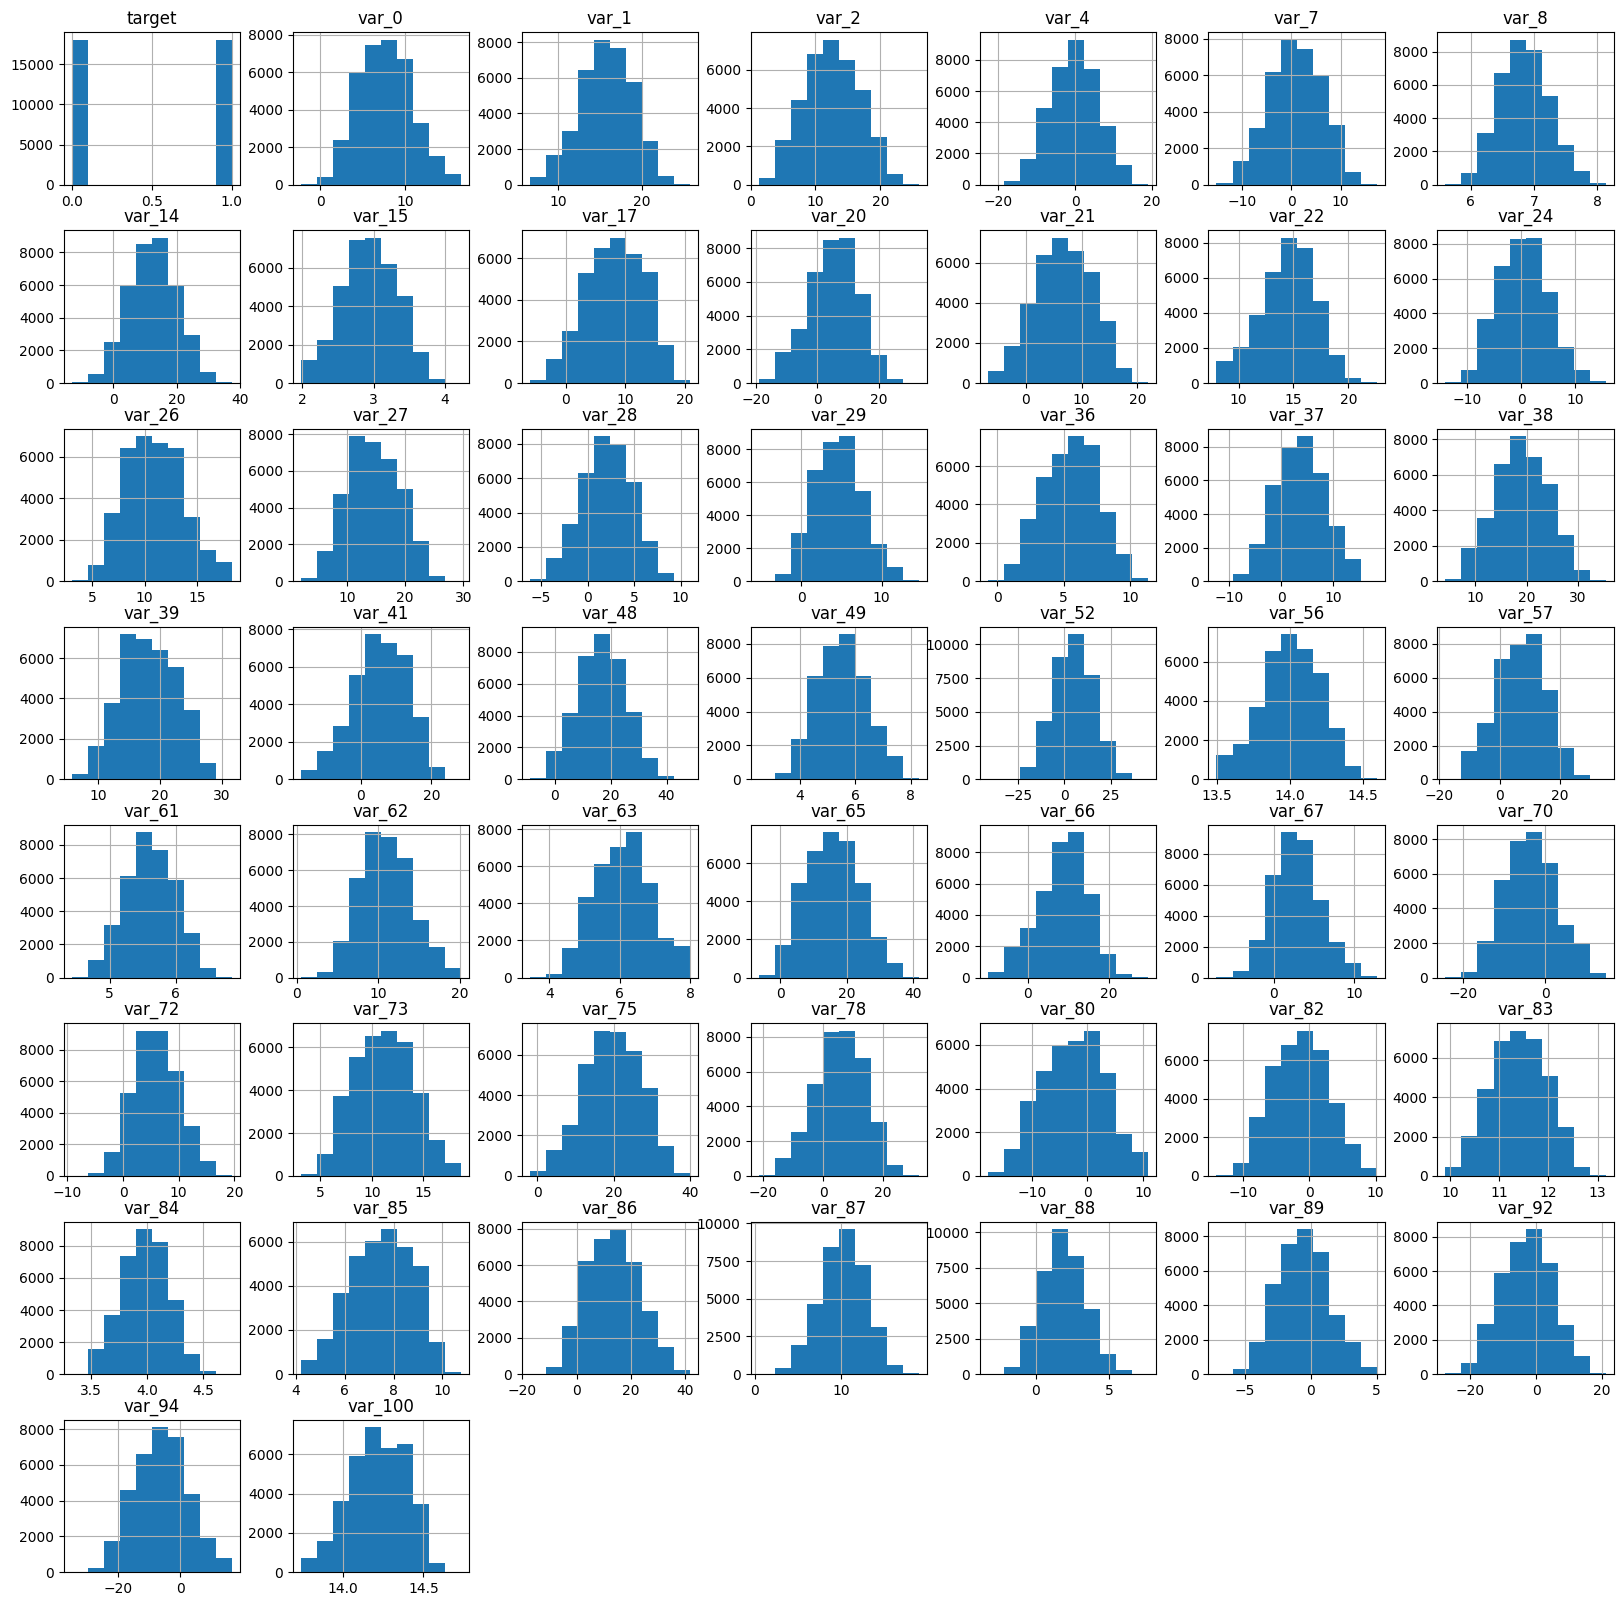

In [ ]:
# Display a histogram
df.hist(figsize=(20, 20)) ;

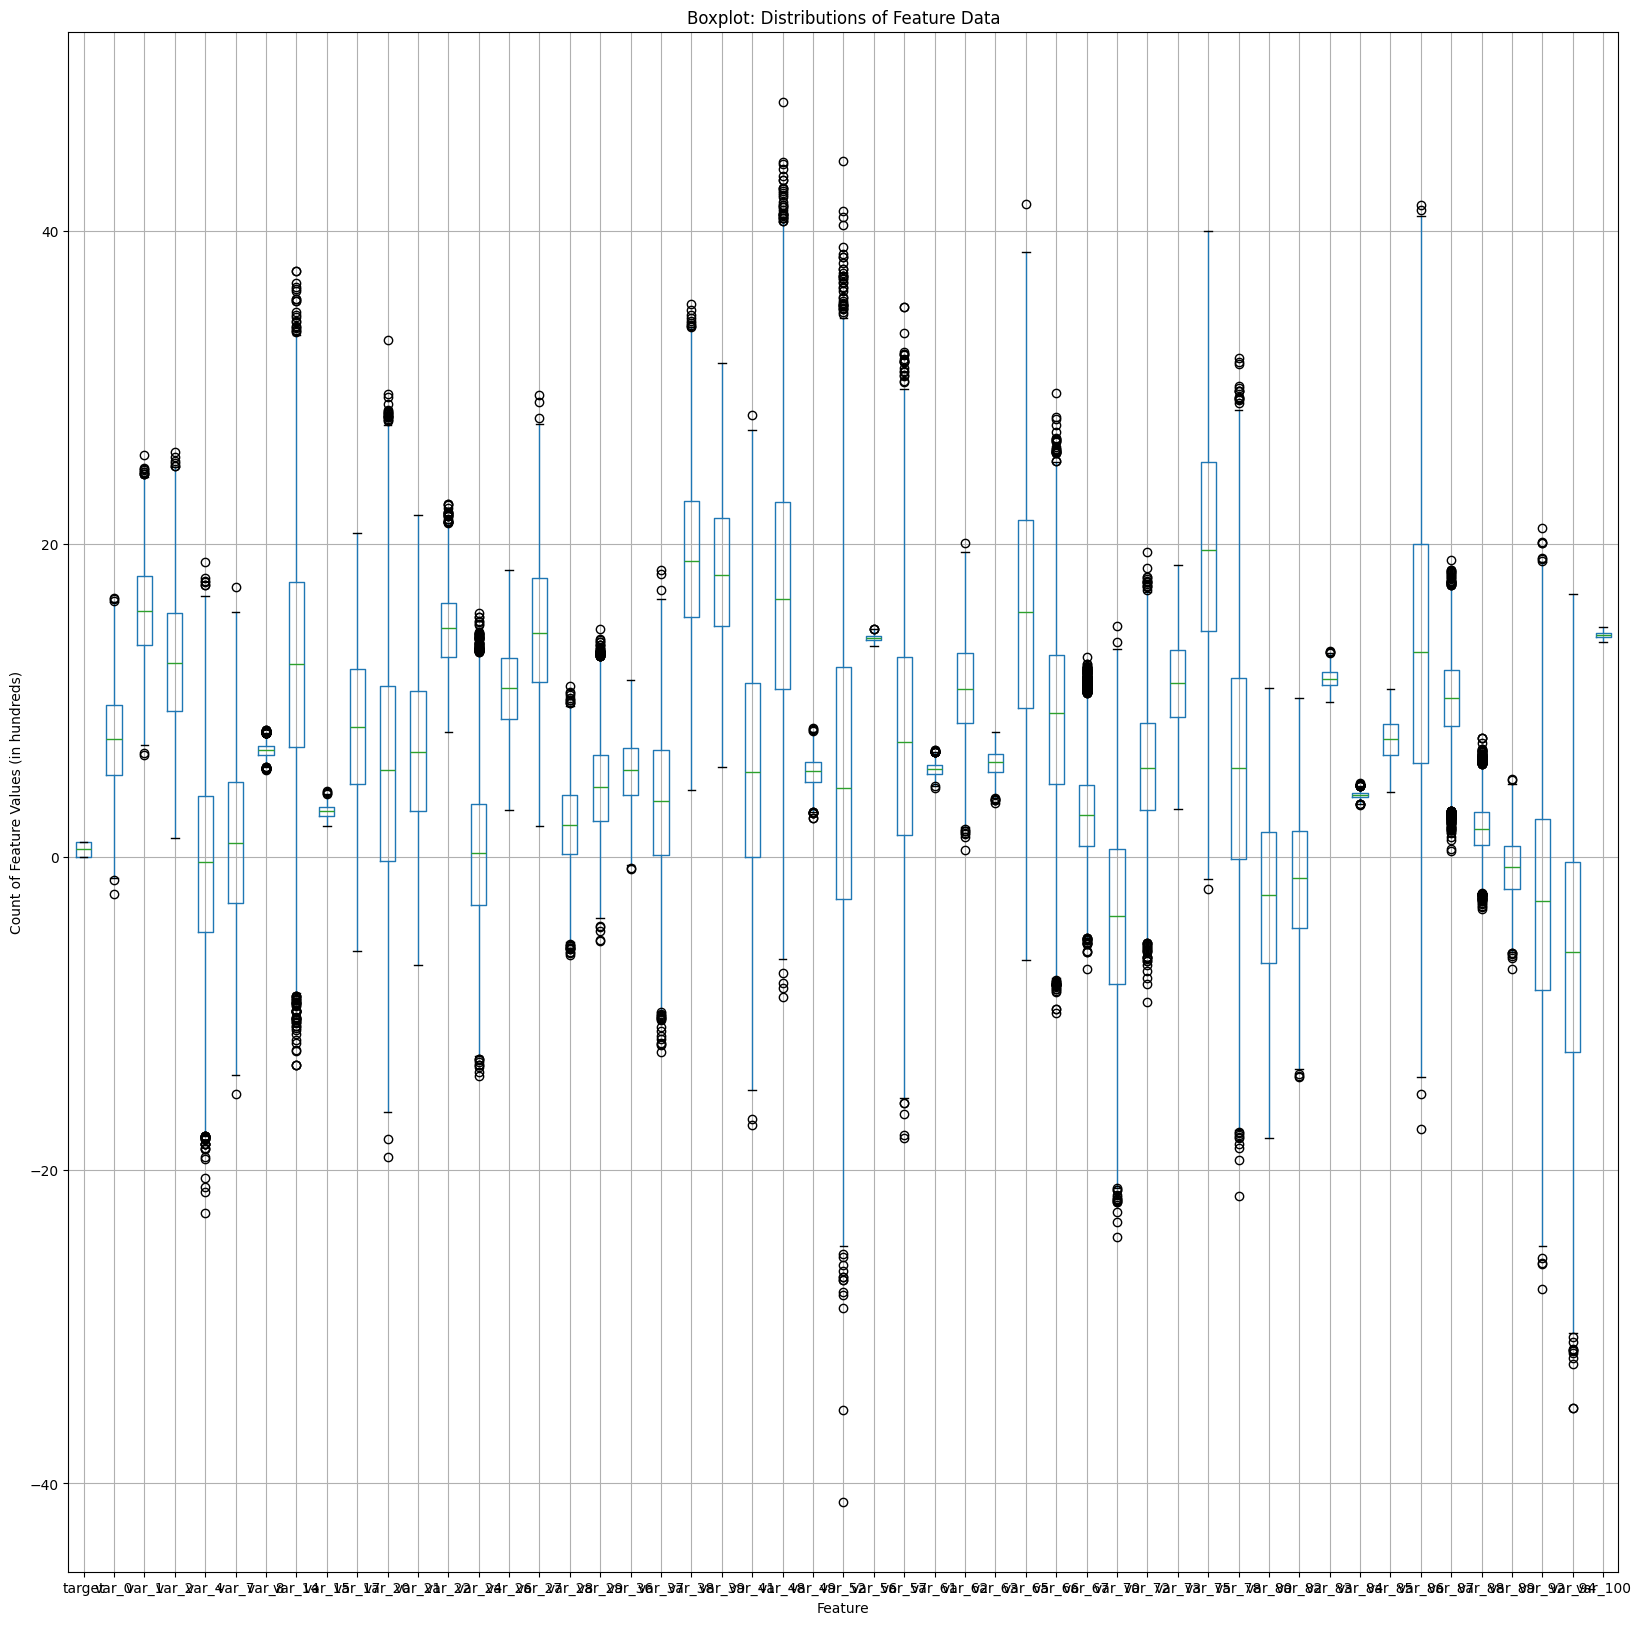

In [ ]:
# display a boxplot
df.boxplot(figsize=(20, 20))
plt.title("Boxplot: Distributions of Feature Data")
plt.xlabel("Feature")
plt.ylabel("Count of Feature Values (in hundreds)") ;

Text(70.72222222222221, 0.5, 'Features')

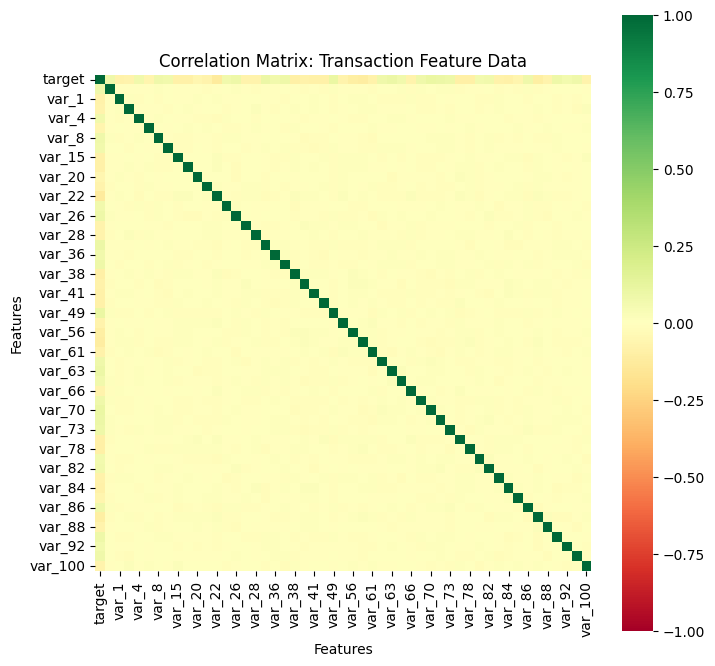

In [ ]:
# column correlations
column_correlations = df.corr()

# Display correlation matrix
plt.figure(figsize = (8, 8))
sns.heatmap(
    column_correlations,
    annot = False,
    square = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)
plt.title("Correlation Matrix: Transaction Feature Data")
plt.xlabel("Features")
plt.ylabel("Features")

## Processing



In [ ]:
target_col = 'target'

### Random Forest Classification

In [ ]:
features = df.drop(target_col, axis = 1)
target = df[target_col]
X = features
y = target

In [ ]:
# Multiple CV — loop count
n = 30

# Create array to hold results (accuracies)
accuracies = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.25 )

  # Create an empty GNB model
  model = RandomForestClassifier(n_estimators = 10)  # Arbitrarily choosing max_depth of 3

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies[i] = metrics.accuracy_score(y_test, y_pred)

In [ ]:
# Calculate mean of results
mean_accuracy = accuracies.mean()
mean_accuracy

np.float64(0.6571286031042128)

### How do we choose the number of trees?

In [ ]:
loops_count = 30

In [ ]:
num_trees = range(10,51,10)
acc_depth = np.zeros(len(num_trees))
std_depth = np.zeros(len(num_trees))

numLoops = loops_count

for n, trees in enumerate(num_trees):
  accuracies = np.zeros(numLoops)

  for i in range(0,numLoops):
    # Train Test Split
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.25 )

    # Create an empty GNB model
    model = RandomForestClassifier(
        n_estimators = trees,
        max_depth = 15,
        min_samples_leaf = 5,
        min_samples_split = 20,
        n_jobs = -1
    )

    # Train ( fit ) the model
    model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = model.predict(X_test)

    # Calculate the accuracy and save to array
    accuracies[i] = metrics.accuracy_score(y_test, y_pred)

  print(trees,' trees finished.')
  acc_depth[n] = accuracies.mean()
  std_depth[n] = accuracies.std( ddof = 1 )


10  trees finished.
20  trees finished.
30  trees finished.
40  trees finished.
50  trees finished.


In [ ]:
pd.DataFrame( zip( num_trees, acc_depth, std_depth ), columns = "treeno accuracy STDev".split() )


,treeno,accuracy,STDev
0,10,0.689970,0.004571
1,20,0.708248,0.004788
2,30,0.714150,0.005815
3,40,0.718208,0.006152
4,50,0.721371,0.003985


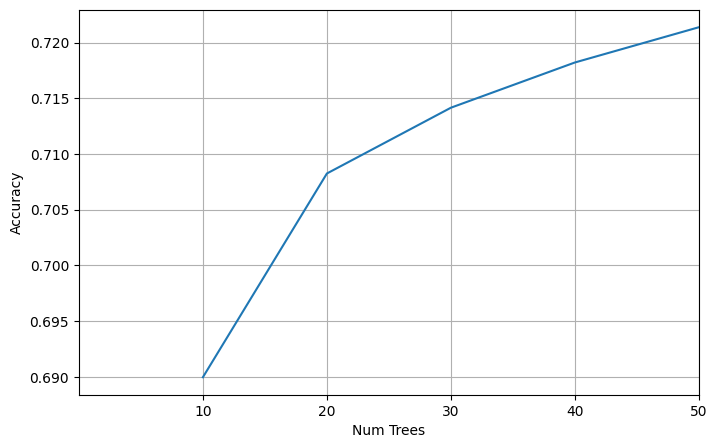

In [ ]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(num_trees, acc_depth)
plt.xlabel('Num Trees')
plt.ylabel('Accuracy')
plt.xlim(0, 20.5)
plt.xticks(num_trees)
plt.grid()


In [ ]:
num_trees = range(10,100,22)
acc_depth = np.zeros(len(num_trees))
std_depth = np.zeros(len(num_trees))

numLoops = loops_count

for n, trees in enumerate(num_trees):
  accuracies = np.zeros(numLoops)

  for i in range(0,numLoops):
    # Train Test Split
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.25 )

    # Create an empty GNB model
    model = RandomForestClassifier(
        n_estimators = trees,
        max_depth = 15,
        min_samples_leaf = 5,
        min_samples_split = 20,
        n_jobs = -1
    )

    # Train ( fit ) the model
    model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = model.predict(X_test)

    # Calculate the accuracy and save to array
    accuracies[i] = metrics.accuracy_score(y_test, y_pred)

  print(trees,' trees finished.')
  acc_depth[n] = accuracies.mean()
  std_depth[n] = accuracies.std( ddof = 1 )


10  trees finished.
32  trees finished.
54  trees finished.
76  trees finished.
98  trees finished.


In [ ]:
pd.DataFrame( zip( num_trees, acc_depth, std_depth ), columns = "treeno accuracy STDev".split() )


,treeno,accuracy,STDev
0,10,0.689605,0.005189
1,32,0.714143,0.004926
2,54,0.722542,0.005438
3,76,0.725429,0.004673
4,98,0.726101,0.004941


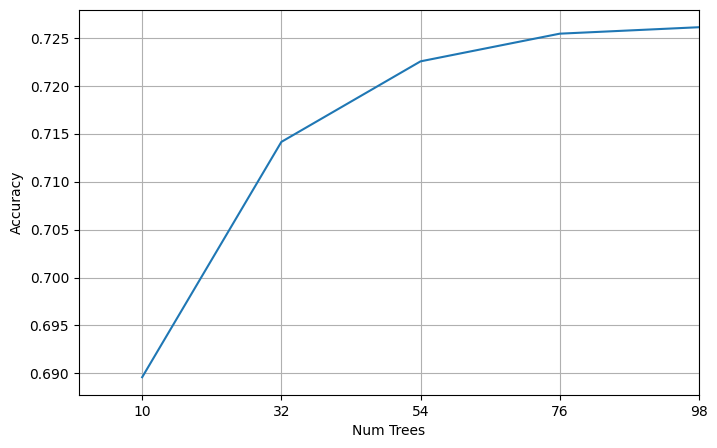

In [ ]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(num_trees, acc_depth)
plt.xlabel('Num Trees')
plt.ylabel('Accuracy')
plt.xlim(0, 20.5)
plt.xticks(num_trees)
plt.grid()


In [ ]:
# Multiple CV — loop count
n = 30

# Create array to hold results (accuracies)
accuracies = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.25 )

  # Create an empty model
  model = RandomForestClassifier(
    n_estimators = 98,
    max_depth = 15,
    min_samples_leaf = 5,
    min_samples_split = 20,
    n_jobs = -1
  )
  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies[i] = metrics.accuracy_score(y_test, y_pred)

In [ ]:
# Calculate mean of results
mean_accuracy = accuracies.mean()
mean_accuracy

np.float64(0.7262971175166297)

## Data Visualization/Communication of Results


### Visualize the Random Forest

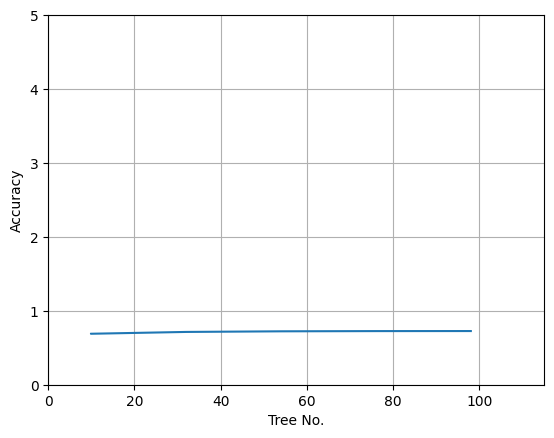

In [ ]:
# plt.errorbar(num_trees, rmse_results, yerr=(std_results*2,std_results*2))
plt.errorbar(num_trees, acc_depth, yerr=std_depth)
plt.xlabel('Tree No.')
plt.ylabel('Accuracy')
plt.ylim(0,5)
plt.xlim(0,115)
plt.grid()

In [ ]:
import graphviz
from IPython.display import display
from sklearn import tree

In [ ]:
len(model.estimators_)

98

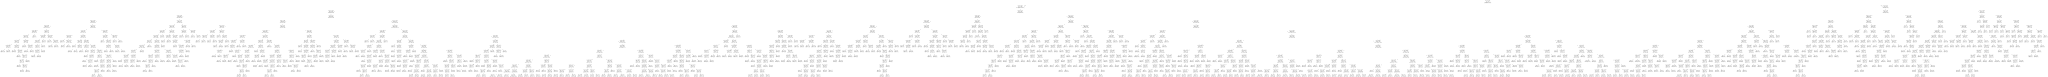

In [ ]:
# Display one tree from the random forest
display(
  graphviz.Source(
    tree.export_graphviz(
      model.estimators_[0],
      feature_names = X.columns,
    )
  )
)

### Find Important Predictors

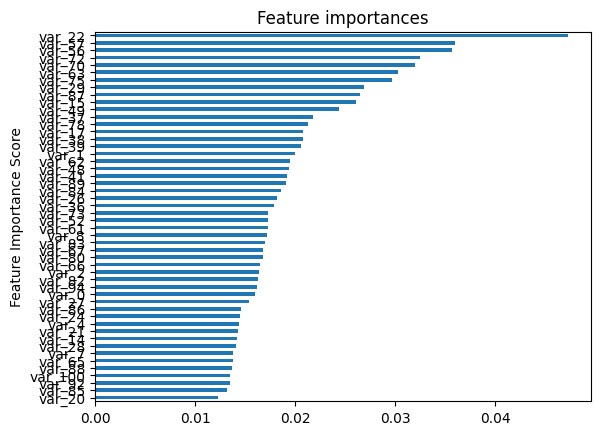

In [ ]:
importances = model.feature_importances_
forest_importances = pd.Series( importances, index = X.columns )

plt.figure()
# forest_importances.plot.bar()
forest_importances.sort_values( ascending = True ).plot.barh()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;

In [ ]:
( forest_importances.sort_values( ascending = False ) * 100 ).cumsum()

,0
var_22,4.726368
var_57,8.324250
var_56,11.890298
var_72,15.142541
var_70,18.338258
var_63,21.363906
var_75,24.329554
var_29,27.015155
var_87,29.664521
var_15,32.276346


### Visualize the Data

Text(0, 0.5, 'Frequency')

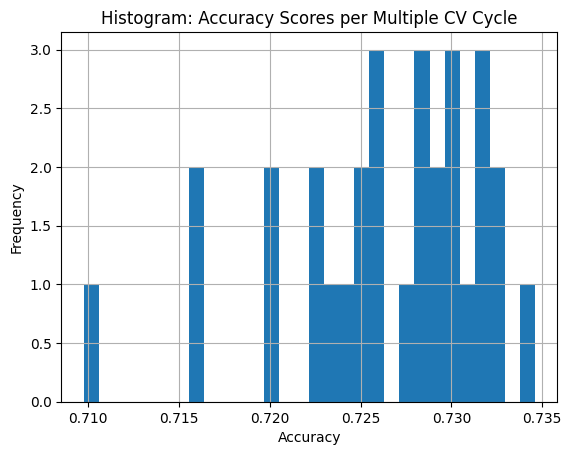

In [ ]:
# Display a histogram of the results
pd.Series(accuracies).hist(bins = 30)
plt.title("Histogram: Accuracy Scores per Multiple CV Cycle")
plt.xlabel("Accuracy")
plt.ylabel("Frequency")

Text(0.5, 1.0, 'Confusion Matrix, Multiple CV')

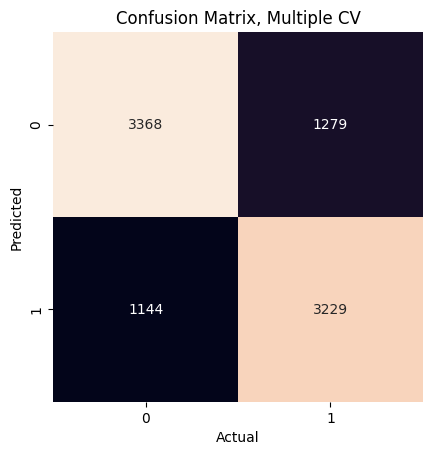

In [ ]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Multiple CV')

In [ ]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.724769,0.746454,0.735451,4512.000000
1.0,0.738395,0.716282,0.727170,4508.000000
accuracy,0.731375,0.731375,0.731375,0.731375
macro avg,0.731582,0.731368,0.731311,9020.000000
weighted avg,0.731579,0.731375,0.731313,9020.000000


## Conclusions

- The best mean accuracy was around 72.6%, which is just about equal to the accuracy using A Gaussian Naive Bayes in Project 1, at around 75.6%.
- Random Forest yielded roughly equivalent false negatives and false positives as GNB.
- Random Forest is about as good as GNB, and has the advantage of not needing to meet the requirements of GNB (normally distributed features, and features are independent).